# Build the VAE of Stable Diffusion

Stable Diffusion (and FADING, the face-aging model built on it) works on 64×64×4 **latents**, not on
pixels. A **VAE** turns a 512×512 photo into a latent and back.

You implement the four layers the VAE is built from. The rest of the model is given. Then you load the
official weights into **your** model, check that it matches the original, and use it to age a face.

Fill in every `# TODO`, then run the check cell. Keep the attribute names: the weights are loaded by name.

## The pipeline

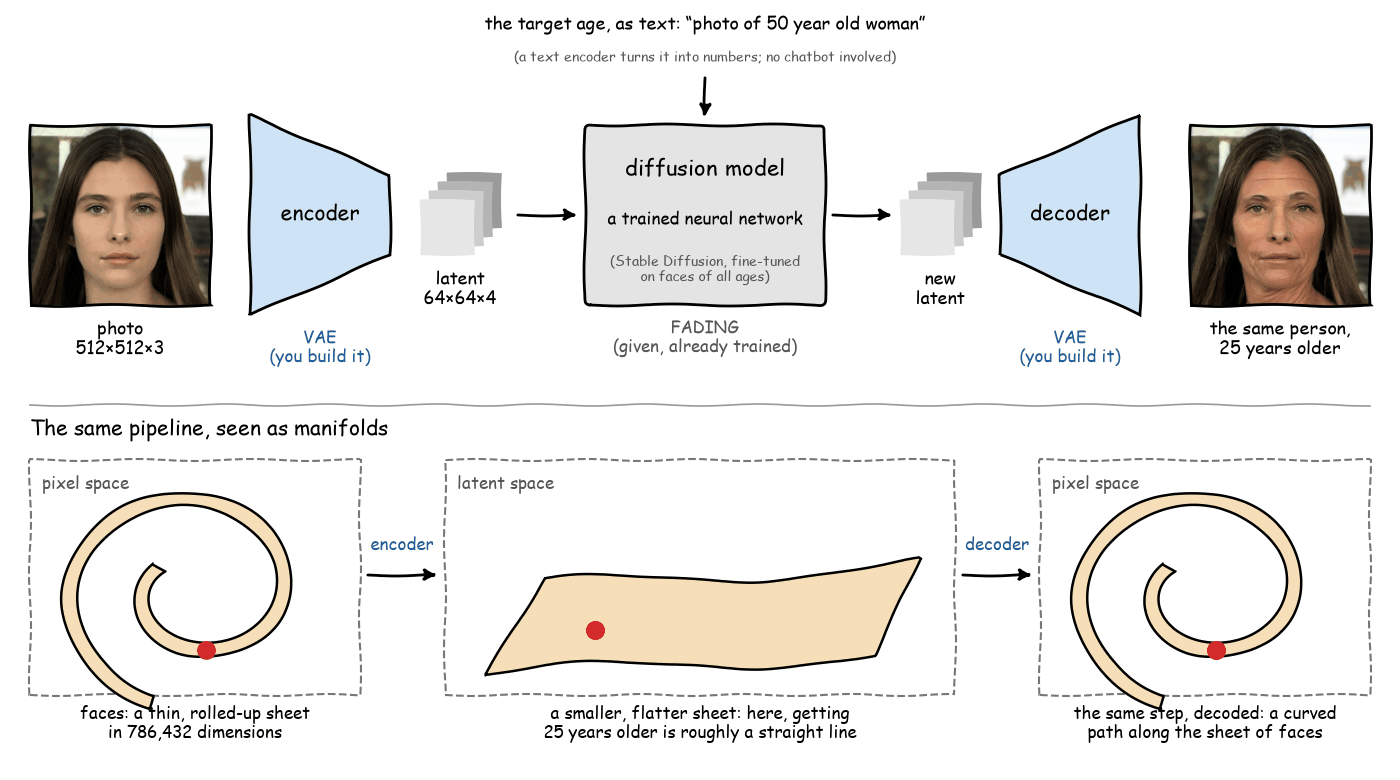

**Top: what happens to the photo.** The **encoder** squeezes the photo into a latent with 48 times fewer
numbers. The **diffusion model** changes the latent. It is a neural network, trained on a huge set of
images (Stable Diffusion) and then on faces of all ages (FADING); it is not a chatbot. The text
"photo of 50 year old woman" only gives it the target age: a text encoder turns it into numbers that
steer the network. The **decoder** turns the new latent back into a photo. Encoder and decoder together
are the VAE, the part you build. The diffusion model is given and already trained; here it is a black box.

**Bottom: the same, as manifolds.** Almost every array of 512×512×3 numbers is noise. Photos of faces fill
only a thin, rolled-up sheet of that space, a manifold. The encoder maps it to a smaller, flatter sheet
in latent space, where getting older is roughly a straight line. The decoder maps every point of that
line back onto the sheet of faces: in pixel space, the same step is a curved path along the roll, and
every point on it is a real photo.

## Setup

In Colab, first pick a GPU: **Runtime → Change runtime type → T4 GPU**.

In [ ]:
# @title Setup (run it, no need to read it)
# Installs the packages Colab lacks and writes the helper code (the FADING diffusion pipeline, image
# grids, renaming of the official weights, downloads) to ~/.cache/bmai_face_aging. Safe to re-run.
import sys
from pathlib import Path

%pip install -q diffusers==0.41.0 transformers==5.19.0 accelerate==1.15.0 safetensors==0.8.0 huggingface_hub==1.33.0 gdown==6.4.2
if "google.colab" in sys.modules:
    %pip uninstall -q -y torchao  # Colab's preinstalled torchao breaks diffusers 0.41; not needed here

HELPERS = Path.home() / ".cache" / "bmai_face_aging"
FILES = {
    'fading/__init__.py': r'''"""Minimal FADING face-aging pipeline with a pluggable VAE (see pipeline.py)."""

from .null_inversion import load_512
from .pipeline import FadingPipeline, Inversion, VAEAdapter, edit_prompt, person_placeholder, source_prompt

__all__ = [
    "FadingPipeline",
    "Inversion",
    "VAEAdapter",
    "edit_prompt",
    "load_512",
    "person_placeholder",
    "source_prompt",
]
''',
    'fading/pipeline.py': r'''"""A minimal FADING face-aging pipeline (Chen & Lathuiliere, "Face Aging via Diffusion-based Editing", BMVC 2023).

FADING = Stable Diffusion v1.5 whose U-Net was briefly fine-tuned on faces with
age prompts ("photo of a 35 year old person"), plus null-text inversion and
prompt-to-prompt editing:

    photo --VAE encoder--> z0 --DDIM inversion + null-text optimisation--> zT
    zT --U-Net, "photo of 30 year old man" vs "photo of 70 year old man", attention control--> z0'
    z0' --VAE decoder--> aged photo

The VAE appears at exactly two places: encoding the input photo and decoding the
result. ``VAEAdapter`` makes any VAE (the original one, or one of ours) usable there.

The official FADING code (github.com/MunchkinChen/FADING) targets diffusers 0.10 and
has no license; this module re-implements its age-editing procedure on current
diffusers, reusing the Apache-2.0 prompt-to-prompt code of Google (see p2p.py,
null_inversion.py, seq_aligner.py). Prompts and hyper-parameters follow FADING's
age_editing.py.
"""

from __future__ import annotations

import time
from dataclasses import dataclass
from pathlib import Path

import numpy as np
import torch

from .null_inversion import NullInversion
from .p2p import AttentionReplace, LocalBlend, register_attention_control

NUM_DDIM_STEPS = 50
GUIDANCE_SCALE = 7.5
CROSS_REPLACE_STEPS = {"default_": 0.8}  # replace cross-attention during the first 80% of the steps
SELF_REPLACE_STEPS = 0.5  # replace self-attention (<= 32x32) during the first 50% of the steps


# ============================================================================ VAEs
class VAEAdapter:
    """Pixels <-> RAW latents for any VAE. The pipeline applies the scaling factor itself.

    Args:
        name: Label used in figures ("teacher", "student", ...).
        vae: A ``diffusers.AutoencoderKL`` or our ``vae.AutoencoderKL``.
    """

    def __init__(self, name: str, vae: torch.nn.Module) -> None:
        self.name = name
        self.vae = vae.eval().requires_grad_(False)
        self.is_diffusers = hasattr(vae, "config") and hasattr(vae.config, "scaling_factor")
        self.scaling_factor = float(vae.config.scaling_factor if self.is_diffusers else vae.scaling_factor)

    @property
    def dtype(self) -> torch.dtype:
        return next(self.vae.parameters()).dtype

    @torch.no_grad()
    def encode(self, images: torch.Tensor) -> torch.Tensor:
        """(B, 3, H, W) in [-1, 1] -> posterior mean (B, 4, H/8, W/8), raw (unscaled), float32."""
        images = images.to(self.dtype)
        posterior = self.vae.encode(images).latent_dist if self.is_diffusers else self.vae.encode(images)
        return posterior.mean.float()

    @torch.no_grad()
    def decode(self, latents: torch.Tensor) -> torch.Tensor:
        """Raw latents -> images (B, 3, H, W), roughly in [-1, 1], float32."""
        latents = latents.to(self.dtype)
        images = self.vae.decode(latents).sample if self.is_diffusers else self.vae.decode(latents)
        return images.float()


def latents_to_uint8(vae: VAEAdapter, latents: torch.Tensor) -> np.ndarray:
    """SCALED latents (what the U-Net produces) -> uint8 images (B, H, W, 3)."""
    images = vae.decode(latents / vae.scaling_factor)
    images = (images / 2 + 0.5).clamp(0, 1)
    return (images.permute(0, 2, 3, 1).cpu().numpy() * 255).astype(np.uint8)


# ============================================================================ prompts
def person_placeholder(age: int, gender: str) -> str:
    """The noun FADING puts in the prompt: 'boy'/'girl' up to age 15, otherwise 'man'/'woman'."""
    is_female = gender == "female"
    if age and age <= 15:  # as in FADING, age 0 counts as an adult
        return "girl" if is_female else "boy"
    return "woman" if is_female else "man"


def source_prompt(age: int, gender: str) -> str:
    return f"photo of {age} year old {person_placeholder(age, gender)}"


def edit_prompt(age_init: int, age_new: int, gender: str) -> str:
    """Swap the age and (if needed) the noun of the source prompt."""
    old_person, new_person = person_placeholder(age_init, gender), person_placeholder(age_new, gender)
    return source_prompt(age_init, gender).replace(old_person, new_person).replace(str(age_init), str(age_new))


# ============================================================================ pipeline
@dataclass
class Inversion:
    """Everything needed to edit one photo: the encoded latent, the inverted noise and null embeddings."""

    vae_name: str
    image: np.ndarray  # (512, 512, 3) uint8 input after cropping/resizing
    z0: torch.Tensor  # scaled latent of the input
    zT: torch.Tensor  # inverted noise
    null_embeddings: list[torch.Tensor]
    seconds: float

    def save(self, path: str | Path) -> None:
        """Save the tensors (the photo itself is not stored)."""
        torch.save(
            {
                "vae_name": self.vae_name,
                "z0": self.z0.cpu(),
                "zT": self.zT.cpu(),
                "null_embeddings": [e.cpu() for e in self.null_embeddings],
                "seconds": self.seconds,
            },
            path,
        )

    @classmethod
    def load(cls, path: str | Path, image: np.ndarray, device: torch.device) -> Inversion:
        state = torch.load(path, map_location="cpu", weights_only=True)
        return cls(
            state["vae_name"],
            image,
            state["z0"].to(device),
            state["zT"].to(device),
            [e.to(device) for e in state["null_embeddings"]],
            state["seconds"],
        )


class FadingPipeline:
    """FADING's specialised U-Net + CLIP text encoder + DDIM scheduler, with a pluggable VAE.

    Build it with :meth:`from_pretrained` from the extracted FADING weights, or directly
    from components (as the tests do with a tiny U-Net). Everything runs in float32, as in FADING.
    """

    def __init__(
        self,
        unet: torch.nn.Module,
        text_encoder: torch.nn.Module,
        tokenizer,
        device: torch.device,
        num_ddim_steps: int = NUM_DDIM_STEPS,
        guidance_scale: float = GUIDANCE_SCALE,
    ) -> None:
        from diffusers import DDIMScheduler

        self.device = device
        self.unet = unet.to(device).requires_grad_(False).eval()
        self.text_encoder = text_encoder.to(device).requires_grad_(False).eval()
        self.tokenizer = tokenizer
        self.num_ddim_steps, self.guidance_scale = num_ddim_steps, guidance_scale
        # FADING's scheduler: DDIM with the SD v1 noise schedule.
        self.scheduler = DDIMScheduler(
            beta_start=0.00085,
            beta_end=0.012,
            beta_schedule="scaled_linear",
            clip_sample=False,
            set_alpha_to_one=False,
            steps_offset=1,
        )
        self.default_processors = dict(self.unet.attn_processors)

    def restore_default_attention(self) -> None:
        # Pass a copy: diffusers' set_attn_processor empties the dict it is given.
        self.unet.set_attn_processor(dict(self.default_processors))

    @classmethod
    def from_pretrained(cls, model_dir: str | Path, device: torch.device, **kwargs) -> FadingPipeline:
        """Load from the extracted FADING weights (a diffusers StableDiffusionPipeline folder,
        e.g. ``weights/fading/finetune_double_prompt_150_random``). The VAE in that folder is not used."""
        from diffusers import UNet2DConditionModel
        from transformers import CLIPTextModel, CLIPTokenizer

        model_dir = Path(model_dir)
        tokenizer = CLIPTokenizer.from_pretrained(model_dir / "tokenizer")
        text_encoder = CLIPTextModel.from_pretrained(model_dir / "text_encoder")
        unet = UNet2DConditionModel.from_pretrained(model_dir / "unet")
        return cls(unet, text_encoder, tokenizer, device, **kwargs)

    # ------------------------------------------------------------------ step 1: inversion
    def invert(
        self, image: np.ndarray, age_init: int, gender: str, vae: VAEAdapter, num_inner_steps: int = 10
    ) -> Inversion:
        """Null-text inversion of a (512, 512, 3) uint8 photo, encoded with ``vae``."""
        start = time.time()
        self.restore_default_attention()
        inverter = NullInversion(
            self.unet, self.text_encoder, self.tokenizer, self.scheduler, vae, self.num_ddim_steps, self.guidance_scale
        )
        # Null-text optimisation backpropagates through the whole U-Net. Gradient checkpointing
        # (same maths, activations recomputed during backward) cuts its memory use several times.
        self.unet.enable_gradient_checkpointing()
        try:
            z0, zT, null_embeddings = inverter.invert(image, source_prompt(age_init, gender), num_inner_steps=num_inner_steps)
        finally:
            self.unet.disable_gradient_checkpointing()
        return Inversion(vae.name, image, z0, zT, null_embeddings, time.time() - start)

    # ------------------------------------------------------------------ step 2: editing
    @torch.no_grad()
    def edit(self, inversion: Inversion, age_init: int, age_new: int, gender: str, vae: VAEAdapter) -> np.ndarray:
        """Generate the photo at ``age_new``. Returns a (512, 512, 3) uint8 image decoded with ``vae``."""
        prompts = [source_prompt(age_init, gender), edit_prompt(age_init, age_new, gender)]
        blend_words = (
            (str(age_init), person_placeholder(age_init, gender)),
            (str(age_new), person_placeholder(age_new, gender)),
        )
        local_blend = LocalBlend(prompts, blend_words, self.tokenizer, self.device, self.num_ddim_steps)
        controller = AttentionReplace(
            prompts, self.num_ddim_steps, CROSS_REPLACE_STEPS, SELF_REPLACE_STEPS, local_blend, self.tokenizer, self.device
        )
        register_attention_control(self.unet, controller)
        try:
            text_input = self.tokenizer(
                prompts, padding="max_length", max_length=self.tokenizer.model_max_length, truncation=True, return_tensors="pt"
            )
            text_embeddings = self.text_encoder(text_input.input_ids.to(self.device))[0]
            latents = inversion.zT.expand(len(prompts), *inversion.zT.shape[1:]).to(self.device)
            self.scheduler.set_timesteps(self.num_ddim_steps)
            for i, t in enumerate(self.scheduler.timesteps):
                # Batch: [null source, null edit, text source, text edit]
                context = torch.cat([inversion.null_embeddings[i].expand(*text_embeddings.shape), text_embeddings])
                noise_pred = self.unet(torch.cat([latents] * 2), t, encoder_hidden_states=context).sample
                noise_uncond, noise_text = noise_pred.chunk(2)
                noise_pred = noise_uncond + self.guidance_scale * (noise_text - noise_uncond)
                latents = self.scheduler.step(noise_pred, t, latents).prev_sample
                latents = controller.step_callback(latents)  # LocalBlend
        finally:
            self.restore_default_attention()
        return latents_to_uint8(vae, latents[1:].float())[0]

    @torch.no_grad()
    def reconstruct(self, image: np.ndarray, vae: VAEAdapter) -> np.ndarray:
        """Plain VAE round trip (no diffusion): what the VAE alone does to the photo."""
        x = torch.from_numpy(image).float().permute(2, 0, 1).unsqueeze(0).to(self.device) / 127.5 - 1
        return latents_to_uint8(vae, vae.encode(x) * vae.scaling_factor)[0]
''',
    'fading/null_inversion.py': r'''# Copyright 2022 Google LLC
#
# Licensed under the Apache License, Version 2.0 (the "License");
# you may not use this file except in compliance with the License.
# You may obtain a copy of the License at
#
#      http://www.apache.org/licenses/LICENSE-2.0
#
# Unless required by applicable law or agreed to in writing, software
# distributed under the License is distributed on an "AS IS" BASIS,
# WITHOUT WARRANTIES OR CONDITIONS OF ANY KIND, either express or implied.
# See the License for the specific language governing permissions and
# limitations under the License.
#
# Modified for this teaching project: ported from google/prompt-to-prompt
# (null_text_w_ptp.ipynb, commit 9c472e4). Changes: no global variables; the VAE is passed in
# through a small adapter, so that any VAE (the original or a student's) can encode the image;
# progress printing instead of tqdm.notebook; type hints and comments.
"""Null-text inversion (Mokady et al., 2023): find the noise and "empty prompt" embeddings that
make Stable Diffusion's DDIM sampler reproduce a given real image.

1. Encode the image with the VAE: z0 = mean of q(z | x), times the scaling factor.
2. DDIM inversion: run the deterministic DDIM sampler *backwards* with the source prompt
   (no classifier-free guidance) to get the trajectory z0 -> z1 -> ... -> zT.
3. Null-text optimisation: sampling forwards from zT with guidance 7.5 drifts away from that
   trajectory. At every step, optimise the unconditional ("null") text embedding so that one
   guided DDIM step lands back on the inverted trajectory.

Editing then starts from zT with the optimised null embeddings, and stays faithful to the photo.
"""

from __future__ import annotations

import time

import numpy as np
import torch
import torch.nn.functional as F
from PIL import Image


def load_512(image: str | Image.Image | np.ndarray, left: int = 0, right: int = 0, top: int = 0, bottom: int = 0) -> np.ndarray:
    """Centre-crop to a square and resize to 512x512 (bicubic). Returns an (512, 512, 3) uint8 array."""
    if isinstance(image, str):
        image = np.array(Image.open(image).convert("RGB"))
    elif isinstance(image, Image.Image):
        image = np.array(image.convert("RGB"))
    image = image[:, :, :3]
    h, w, _ = image.shape
    left = min(left, w - 1)
    right = min(right, w - left - 1)
    top = min(top, h - left - 1)
    bottom = min(bottom, h - top - 1)
    image = image[top : h - bottom, left : w - right]
    h, w, _ = image.shape
    if h < w:
        offset = (w - h) // 2
        image = image[:, offset : offset + h]
    elif w < h:
        offset = (h - w) // 2
        image = image[offset : offset + w]
    return np.array(Image.fromarray(image).resize((512, 512), Image.Resampling.BICUBIC))


class NullInversion:
    """Invert a real image into Stable Diffusion's DDIM sampler.

    Args:
        unet, text_encoder, tokenizer, scheduler: Stable Diffusion components (FADING's U-Net).
        vae: A ``VAEAdapter`` (encodes pixels to raw latents).
        num_ddim_steps: Number of DDIM steps (50 in FADING).
        guidance_scale: Classifier-free guidance scale (7.5 in FADING).
    """

    def __init__(self, unet, text_encoder, tokenizer, scheduler, vae, num_ddim_steps: int = 50, guidance_scale: float = 7.5):
        self.unet = unet
        self.text_encoder = text_encoder
        self.tokenizer = tokenizer
        self.scheduler = scheduler
        self.vae = vae
        self.num_ddim_steps = num_ddim_steps
        self.guidance_scale = guidance_scale
        self.scheduler.set_timesteps(num_ddim_steps)
        self.context: torch.Tensor | None = None

    @property
    def device(self) -> torch.device:
        return self.unet.device

    # ------------------------------------------------------------------ DDIM steps
    def prev_step(self, model_output: torch.Tensor, timestep: int, sample: torch.Tensor) -> torch.Tensor:
        """One deterministic DDIM step towards less noise (t -> t - 1000 / num_steps)."""
        prev_timestep = timestep - self.scheduler.config.num_train_timesteps // self.scheduler.num_inference_steps
        alpha_prod_t = self.scheduler.alphas_cumprod[timestep]
        alpha_prod_t_prev = (
            self.scheduler.alphas_cumprod[prev_timestep] if prev_timestep >= 0 else self.scheduler.final_alpha_cumprod
        )
        beta_prod_t = 1 - alpha_prod_t
        pred_original_sample = (sample - beta_prod_t**0.5 * model_output) / alpha_prod_t**0.5
        pred_sample_direction = (1 - alpha_prod_t_prev) ** 0.5 * model_output
        return alpha_prod_t_prev**0.5 * pred_original_sample + pred_sample_direction

    def next_step(self, model_output: torch.Tensor, timestep: int, sample: torch.Tensor) -> torch.Tensor:
        """One deterministic DDIM step towards MORE noise: the inverse of ``prev_step``."""
        timestep, next_timestep = (
            min(timestep - self.scheduler.config.num_train_timesteps // self.scheduler.num_inference_steps, 999),
            timestep,
        )
        alpha_prod_t = self.scheduler.alphas_cumprod[timestep] if timestep >= 0 else self.scheduler.final_alpha_cumprod
        alpha_prod_t_next = self.scheduler.alphas_cumprod[next_timestep]
        beta_prod_t = 1 - alpha_prod_t
        next_original_sample = (sample - beta_prod_t**0.5 * model_output) / alpha_prod_t**0.5
        next_sample_direction = (1 - alpha_prod_t_next) ** 0.5 * model_output
        return alpha_prod_t_next**0.5 * next_original_sample + next_sample_direction

    def get_noise_pred_single(self, latents: torch.Tensor, t, context: torch.Tensor) -> torch.Tensor:
        return self.unet(latents, t, encoder_hidden_states=context).sample

    def get_noise_pred(self, latents: torch.Tensor, t, is_forward: bool = True, context: torch.Tensor | None = None):
        latents_input = torch.cat([latents] * 2)
        if context is None:
            context = self.context
        guidance_scale = 1 if is_forward else self.guidance_scale
        noise_pred = self.unet(latents_input, t, encoder_hidden_states=context).sample
        noise_pred_uncond, noise_prediction_text = noise_pred.chunk(2)
        noise_pred = noise_pred_uncond + guidance_scale * (noise_prediction_text - noise_pred_uncond)
        if is_forward:
            return self.next_step(noise_pred, t, latents)
        return self.prev_step(noise_pred, t, latents)

    # ------------------------------------------------------------------ inversion
    @torch.no_grad()
    def image2latent(self, image: np.ndarray) -> torch.Tensor:
        """uint8 image (512, 512, 3) -> scaled latent (1, 4, 64, 64), using the posterior MEAN."""
        x = torch.from_numpy(image).float() / 127.5 - 1
        x = x.permute(2, 0, 1).unsqueeze(0).to(self.device)
        return self.vae.encode(x) * self.vae.scaling_factor

    @torch.no_grad()
    def init_prompt(self, prompt: str) -> None:
        uncond_input = self.tokenizer(
            [""], padding="max_length", max_length=self.tokenizer.model_max_length, return_tensors="pt"
        )
        uncond_embeddings = self.text_encoder(uncond_input.input_ids.to(self.device))[0]
        text_input = self.tokenizer(
            [prompt], padding="max_length", max_length=self.tokenizer.model_max_length, truncation=True, return_tensors="pt"
        )
        text_embeddings = self.text_encoder(text_input.input_ids.to(self.device))[0]
        self.context = torch.cat([uncond_embeddings, text_embeddings])

    @torch.no_grad()
    def ddim_loop(self, latent: torch.Tensor) -> list[torch.Tensor]:
        """DDIM inversion with the source prompt only: z0 -> z1 -> ... -> zT (num_ddim_steps + 1 latents)."""
        _, cond_embeddings = self.context.chunk(2)
        all_latent = [latent]
        latent = latent.clone().detach()
        for i in range(self.num_ddim_steps):
            t = self.scheduler.timesteps[len(self.scheduler.timesteps) - i - 1]
            noise_pred = self.get_noise_pred_single(latent, t, cond_embeddings)
            latent = self.next_step(noise_pred, t, latent)
            all_latent.append(latent)
        return all_latent

    def null_optimization(
        self, latents: list[torch.Tensor], num_inner_steps: int, epsilon: float, verbose: bool = True
    ) -> list[torch.Tensor]:
        """Optimise one unconditional embedding per step so that guided DDIM retraces ``latents``."""
        uncond_embeddings, cond_embeddings = self.context.chunk(2)
        uncond_embeddings_list = []
        latent_cur = latents[-1]
        start = time.time()
        for i in range(self.num_ddim_steps):
            uncond_embeddings = uncond_embeddings.clone().detach()
            uncond_embeddings.requires_grad = True
            optimizer = torch.optim.Adam([uncond_embeddings], lr=1e-2 * (1.0 - i / 100.0))
            latent_prev = latents[len(latents) - i - 2]
            t = self.scheduler.timesteps[i]
            with torch.no_grad():
                noise_pred_cond = self.get_noise_pred_single(latent_cur, t, cond_embeddings)
            for _ in range(num_inner_steps):
                noise_pred_uncond = self.get_noise_pred_single(latent_cur, t, uncond_embeddings)
                noise_pred = noise_pred_uncond + self.guidance_scale * (noise_pred_cond - noise_pred_uncond)
                latents_prev_rec = self.prev_step(noise_pred, t, latent_cur)
                loss = F.mse_loss(latents_prev_rec, latent_prev)
                optimizer.zero_grad()
                loss.backward()
                optimizer.step()
                if loss.item() < epsilon + i * 2e-5:
                    break
            uncond_embeddings_list.append(uncond_embeddings[:1].detach())
            with torch.no_grad():
                context = torch.cat([uncond_embeddings, cond_embeddings])
                latent_cur = self.get_noise_pred(latent_cur, t, False, context)
            if verbose and (i + 1) % 10 == 0:
                print(f"[inversion]   null-text step {i + 1}/{self.num_ddim_steps} ({time.time() - start:.0f}s)", flush=True)
        return uncond_embeddings_list

    def invert(
        self,
        image: np.ndarray,
        prompt: str,
        num_inner_steps: int = 10,
        early_stop_epsilon: float = 1e-5,
        verbose: bool = True,
    ) -> tuple[torch.Tensor, torch.Tensor, list[torch.Tensor]]:
        """Returns ``(z0, zT, null_embeddings)`` for a (512, 512, 3) uint8 image and its source prompt."""
        self.init_prompt(prompt)
        latent = self.image2latent(image)
        if verbose:
            print("[inversion] DDIM inversion ...", flush=True)
        ddim_latents = self.ddim_loop(latent)
        if verbose:
            print("[inversion] null-text optimisation ...", flush=True)
        uncond_embeddings = self.null_optimization(ddim_latents, num_inner_steps, early_stop_epsilon, verbose)
        return latent, ddim_latents[-1], uncond_embeddings
''',
    'fading/p2p.py': r'''# Copyright 2022 Google LLC
#
# Licensed under the Apache License, Version 2.0 (the "License");
# you may not use this file except in compliance with the License.
# You may obtain a copy of the License at
#
#      http://www.apache.org/licenses/LICENSE-2.0
#
# Unless required by applicable law or agreed to in writing, software
# distributed under the License is distributed on an "AS IS" BASIS,
# WITHOUT WARRANTIES OR CONDITIONS OF ANY KIND, either express or implied.
# See the License for the specific language governing permissions and
# limitations under the License.
#
# Modified for this teaching project: ported from google/prompt-to-prompt
# (null_text_w_ptp.ipynb and ptp_utils.py, commit 9c472e4). Changes:
#  - no global variables: the tokenizer, device and number of steps are arguments;
#  - LocalBlend.get_mask receives x_t (as in FADING's copy of this code);
#  - only what FADING's age edit uses is kept. FADING wraps AttentionReplace in an
#    AttentionReweight whose equalizer is all ones, which changes nothing, so it is omitted;
#  - the attention hook is a diffusers attention processor (P2PAttnProcessor). The original
#    replaced `CrossAttention.forward`, a class that no longer exists in diffusers;
#  - 64x64 self-attention layers, which the controller never stores or edits, are computed with
#    memory-efficient attention instead of materialising their 4096x4096 attention matrices.
"""Prompt-to-prompt (Hertz et al., 2022): edit an image by editing its prompt.

The U-Net's cross-attention maps say which pixels "look at" which words. To change
"photo of 30 year old man" into "photo of 70 year old man" without changing the
person, the edited prompt is generated in parallel with the source prompt, and:

* for the first 80% of the steps, the edited prompt's cross-attention maps are
  replaced by the source prompt's maps (word-swapped): same layout, new words;
* for the first 50% of the steps, its self-attention maps (at <= 32x32) are
  replaced as well: same structure and pose;
* LocalBlend keeps everything outside the region attended by the edited words
  identical to the source (background, clothes).
"""

from __future__ import annotations

import abc

import torch
import torch.nn.functional as F

from .seq_aligner import get_replacement_mapper, get_word_inds

MAX_NUM_WORDS = 77


# ============================================================================ helpers from ptp_utils.py
def update_alpha_time_word(alpha, bounds, prompt_ind, word_inds=None):
    if isinstance(bounds, float):
        bounds = 0, bounds
    start, end = int(bounds[0] * alpha.shape[0]), int(bounds[1] * alpha.shape[0])
    if word_inds is None:
        word_inds = torch.arange(alpha.shape[2])
    alpha[:start, prompt_ind, word_inds] = 0
    alpha[start:end, prompt_ind, word_inds] = 1
    alpha[end:, prompt_ind, word_inds] = 0
    return alpha


def get_time_words_attention_alpha(prompts, num_steps, cross_replace_steps, tokenizer, max_num_words=MAX_NUM_WORDS):
    """For each step and token: 1 if the edited prompt's cross-attention is replaced, else 0."""
    if not isinstance(cross_replace_steps, dict):
        cross_replace_steps = {"default_": cross_replace_steps}
    if "default_" not in cross_replace_steps:
        cross_replace_steps["default_"] = (0.0, 1.0)
    alpha_time_words = torch.zeros(num_steps + 1, len(prompts) - 1, max_num_words)
    for i in range(len(prompts) - 1):
        alpha_time_words = update_alpha_time_word(alpha_time_words, cross_replace_steps["default_"], i)
    for key, item in cross_replace_steps.items():
        if key != "default_":
            inds = [get_word_inds(prompts[i], key, tokenizer) for i in range(1, len(prompts))]
            for i, ind in enumerate(inds):
                if len(ind) > 0:
                    alpha_time_words = update_alpha_time_word(alpha_time_words, item, i, ind)
    return alpha_time_words.reshape(num_steps + 1, len(prompts) - 1, 1, 1, max_num_words)


# ============================================================================ LocalBlend
class LocalBlend:
    """Keep the source latent wherever the edited words are not attended to.

    After every denoising step, the 16x16 cross-attention maps of the blend words
    (summed over all steps so far) are turned into a binary mask. Outside the
    mask, the edited latent is reset to the source latent.
    """

    def __init__(self, prompts, words, tokenizer, device, num_ddim_steps=50, start_blend=0.2, th=(0.3, 0.3)):
        alpha_layers = torch.zeros(len(prompts), 1, 1, 1, 1, MAX_NUM_WORDS)
        for i, (prompt, words_) in enumerate(zip(prompts, words)):
            if isinstance(words_, str):
                words_ = [words_]
            for word in words_:
                ind = get_word_inds(prompt, word, tokenizer)
                alpha_layers[i, :, :, :, :, ind] = 1
        self.alpha_layers = alpha_layers.to(device)
        self.start_blend = int(start_blend * num_ddim_steps)
        self.counter = 0
        self.th = th

    def get_mask(self, x_t, maps, alpha, use_pool):
        k = 1
        maps = (maps * alpha).sum(-1).mean(1)
        if use_pool:
            maps = F.max_pool2d(maps, (k * 2 + 1, k * 2 + 1), (1, 1), padding=(k, k))
        mask = F.interpolate(maps, size=(x_t.shape[2:]))
        mask = mask / mask.max(2, keepdims=True)[0].max(3, keepdims=True)[0]
        mask = mask.gt(self.th[1 - int(use_pool)])
        mask = mask[:1] + mask  # union with the source prompt's mask
        return mask

    def __call__(self, x_t, attention_store):
        self.counter += 1
        if self.counter > self.start_blend:
            maps = attention_store["down_cross"][2:4] + attention_store["up_cross"][:3]  # the 16x16 layers
            maps = [item.reshape(self.alpha_layers.shape[0], -1, 1, 16, 16, MAX_NUM_WORDS) for item in maps]
            maps = torch.cat(maps, dim=1)
            mask = self.get_mask(x_t, maps, self.alpha_layers, True).float()
            x_t = x_t[:1] + mask * (x_t - x_t[:1])
        return x_t


# ============================================================================ controllers
class AttentionControl(abc.ABC):
    """Called by every attention layer of the U-Net with its softmax probabilities.

    The probabilities have shape (batch * heads, queries, keys) for the batch
    [uncond source, uncond edit, cond source, cond edit]; only the conditional
    half is passed to ``forward``.
    """

    def __init__(self) -> None:
        self.cur_step = 0
        self.num_att_layers = -1
        self.cur_att_layer = 0

    def step_callback(self, x_t):
        return x_t

    def between_steps(self) -> None:
        return

    def needs_probabilities(self, is_cross: bool, num_queries: int) -> bool:
        """False for layers whose probabilities the controller never reads or changes."""
        return True

    @abc.abstractmethod
    def forward(self, attn, is_cross: bool, place_in_unet: str):
        raise NotImplementedError

    def __call__(self, attn, is_cross: bool, place_in_unet: str):
        h = attn.shape[0]
        attn[h // 2 :] = self.forward(attn[h // 2 :], is_cross, place_in_unet)
        self.count_layer()
        return attn

    def count_layer(self) -> None:
        self.cur_att_layer += 1
        if self.cur_att_layer == self.num_att_layers:
            self.cur_att_layer = 0
            self.cur_step += 1
            self.between_steps()

    def reset(self) -> None:
        self.cur_step = 0
        self.cur_att_layer = 0


class AttentionStore(AttentionControl):
    """Accumulates the attention maps of layers with at most 32x32 queries (summed over steps)."""

    @staticmethod
    def get_empty_store():
        return {"down_cross": [], "mid_cross": [], "up_cross": [], "down_self": [], "mid_self": [], "up_self": []}

    def __init__(self) -> None:
        super().__init__()
        self.step_store = self.get_empty_store()
        self.attention_store = {}

    def needs_probabilities(self, is_cross: bool, num_queries: int) -> bool:
        return num_queries <= 32**2

    def forward(self, attn, is_cross: bool, place_in_unet: str):
        key = f"{place_in_unet}_{'cross' if is_cross else 'self'}"
        if attn.shape[1] <= 32**2:  # avoid memory overhead
            self.step_store[key].append(attn)
        return attn

    def between_steps(self) -> None:
        if len(self.attention_store) == 0:
            self.attention_store = self.step_store
        else:
            for key in self.attention_store:
                for i in range(len(self.attention_store[key])):
                    self.attention_store[key][i] += self.step_store[key][i]
        self.step_store = self.get_empty_store()

    def reset(self) -> None:
        super().reset()
        self.step_store = self.get_empty_store()
        self.attention_store = {}


class AttentionControlEdit(AttentionStore, abc.ABC):
    def __init__(self, prompts, num_steps, cross_replace_steps, self_replace_steps, local_blend, tokenizer, device):
        super().__init__()
        self.batch_size = len(prompts)
        self.cross_replace_alpha = get_time_words_attention_alpha(prompts, num_steps, cross_replace_steps, tokenizer).to(
            device
        )
        if isinstance(self_replace_steps, float):
            self_replace_steps = 0, self_replace_steps
        self.num_self_replace = int(num_steps * self_replace_steps[0]), int(num_steps * self_replace_steps[1])
        self.local_blend = local_blend

    def step_callback(self, x_t):
        if self.local_blend is not None:
            x_t = self.local_blend(x_t, self.attention_store)
        return x_t

    def needs_probabilities(self, is_cross: bool, num_queries: int) -> bool:
        # Cross-attention is edited at every resolution; self-attention only up to 32x32.
        return is_cross or num_queries <= 32**2

    def replace_self_attention(self, attn_base, att_replace, place_in_unet):
        if att_replace.shape[2] <= 32**2:
            return attn_base.unsqueeze(0).expand(att_replace.shape[0], *attn_base.shape)
        return att_replace

    @abc.abstractmethod
    def replace_cross_attention(self, attn_base, att_replace):
        raise NotImplementedError

    def forward(self, attn, is_cross: bool, place_in_unet: str):
        super().forward(attn, is_cross, place_in_unet)
        if is_cross or (self.num_self_replace[0] <= self.cur_step < self.num_self_replace[1]):
            h = attn.shape[0] // self.batch_size
            attn = attn.reshape(self.batch_size, h, *attn.shape[1:])
            attn_base, attn_replace = attn[0], attn[1:]
            if is_cross:
                alpha_words = self.cross_replace_alpha[self.cur_step]
                attn_replace_new = (
                    self.replace_cross_attention(attn_base, attn_replace) * alpha_words
                    + (1 - alpha_words) * attn_replace
                )
                attn[1:] = attn_replace_new
            else:
                attn[1:] = self.replace_self_attention(attn_base, attn_replace, place_in_unet)
            attn = attn.reshape(self.batch_size * h, *attn.shape[2:])
        return attn


class AttentionReplace(AttentionControlEdit):
    """Word swap: the edited prompt uses the source prompt's cross-attention maps (re-indexed by the mapper)."""

    def __init__(self, prompts, num_steps, cross_replace_steps, self_replace_steps, local_blend, tokenizer, device):
        super().__init__(prompts, num_steps, cross_replace_steps, self_replace_steps, local_blend, tokenizer, device)
        self.mapper = get_replacement_mapper(prompts, tokenizer).to(device)

    def replace_cross_attention(self, attn_base, att_replace):
        return torch.einsum("hpw,bwn->bhpn", attn_base, self.mapper)


# ============================================================================ diffusers hook
class P2PAttnProcessor:
    """A diffusers attention processor that lets a controller read and edit attention probabilities."""

    def __init__(self, controller: AttentionControl, place_in_unet: str) -> None:
        self.controller = controller
        self.place_in_unet = place_in_unet

    def __call__(self, attn, hidden_states, encoder_hidden_states=None, attention_mask=None, temb=None, **kwargs):
        if attention_mask is not None:
            raise NotImplementedError("attention masks are not used by Stable Diffusion's U-Net")
        is_cross = encoder_hidden_states is not None
        context = encoder_hidden_states if is_cross else hidden_states
        query = attn.to_q(hidden_states)
        key = attn.to_k(context)
        value = attn.to_v(context)

        if self.controller.needs_probabilities(is_cross, hidden_states.shape[1]):
            query, key, value = attn.head_to_batch_dim(query), attn.head_to_batch_dim(key), attn.head_to_batch_dim(value)
            probs = attn.get_attention_scores(query, key, None)  # softmax(q k^T * scale)
            probs = self.controller(probs, is_cross, self.place_in_unet)
            out = attn.batch_to_head_dim(torch.bmm(probs, value))
        else:
            # Same maths without keeping the (queries x keys) matrices: for 64x64 self-attention they
            # would take 4 * 8 * 4096 * 4096 floats (2 GB) per layer. One image at a time also keeps
            # backends that do materialise them (e.g. Apple's MPS) at a quarter of that.
            batch, head_dim = query.shape[0], query.shape[-1] // attn.heads
            query, key, value = (t.view(batch, -1, attn.heads, head_dim).transpose(1, 2) for t in (query, key, value))
            out = torch.cat(
                [F.scaled_dot_product_attention(query[i : i + 1], key[i : i + 1], value[i : i + 1]) for i in range(batch)]
            )
            out = out.transpose(1, 2).reshape(batch, -1, attn.heads * head_dim)
            self.controller.count_layer()

        out = attn.to_out[0](out)  # linear projection
        return attn.to_out[1](out)  # dropout


def register_attention_control(unet, controller: AttentionControl) -> None:
    """Route every attention layer of ``unet`` through ``controller``."""
    processors = {}
    for name in unet.attn_processors:
        place = "down" if name.startswith("down_blocks") else "up" if name.startswith("up_blocks") else "mid"
        processors[name] = P2PAttnProcessor(controller, place)
    controller.num_att_layers = len(processors)  # count first: set_attn_processor empties the dict
    unet.set_attn_processor(processors)
''',
    'fading/seq_aligner.py': r'''# Copyright 2022 Google LLC
#
# Licensed under the Apache License, Version 2.0 (the "License");
# you may not use this file except in compliance with the License.
# You may obtain a copy of the License at
#
#      http://www.apache.org/licenses/LICENSE-2.0
#
# Unless required by applicable law or agreed to in writing, software
# distributed under the License is distributed on an "AS IS" BASIS,
# WITHOUT WARRANTIES OR CONDITIONS OF ANY KIND, either express or implied.
# See the License for the specific language governing permissions and
# limitations under the License.
#
# Modified for this teaching project: ported from google/prompt-to-prompt (seq_aligner.py,
# commit 9c472e4). Only the functions needed for a word-swap edit are kept; type hints and
# comments were added. The logic is unchanged, including a quirk in the last branch of
# `get_replacement_mapper_` (it writes mapper[j, j]), so results match the original code.
"""Map the tokens of a source prompt to the tokens of an edited prompt (prompt-to-prompt word swap)."""

from __future__ import annotations

import numpy as np
import torch


def get_word_inds(text: str, word_place: int | str, tokenizer) -> np.ndarray:
    """Token positions (1-based, after <bos>) of a word given by its index or its text.

    CLIP splits some words into several tokens (every digit of an age is its own token:
    "35" -> "3", "5"), so one word can map to several positions.
    """
    split_text = text.split(" ")
    if isinstance(word_place, str):
        word_place = [i for i, word in enumerate(split_text) if word_place == word]
    elif isinstance(word_place, int):
        word_place = [word_place]
    out = []
    if len(word_place) > 0:
        words_encode = [tokenizer.decode([item]).strip("#") for item in tokenizer.encode(text)][1:-1]
        cur_len, ptr = 0, 0
        for i in range(len(words_encode)):
            cur_len += len(words_encode[i])
            if ptr in word_place:
                out.append(i + 1)
            if cur_len >= len(split_text[ptr]):
                ptr += 1
                cur_len = 0
    return np.array(out)


def get_replacement_mapper_(x: str, y: str, tokenizer, max_len: int = 77) -> torch.Tensor:
    """A (max_len, max_len) matrix sending each token of prompt ``x`` to the tokens of prompt ``y``.

    Both prompts must have the same number of words. Words that differ are mapped
    onto each other (spreading the attention evenly when their token counts differ);
    all other tokens map to themselves.
    """
    words_x = x.split(" ")
    words_y = y.split(" ")
    if len(words_x) != len(words_y):
        raise ValueError(
            f"attention replacement edit can only be applied on prompts with the same length"
            f" but prompt A has {len(words_x)} words and prompt B has {len(words_y)} words."
        )
    inds_replace = [i for i in range(len(words_y)) if words_y[i] != words_x[i]]
    inds_source = [get_word_inds(x, i, tokenizer) for i in inds_replace]
    inds_target = [get_word_inds(y, i, tokenizer) for i in inds_replace]
    mapper = np.zeros((max_len, max_len))
    i = j = 0
    cur_inds = 0
    while i < max_len and j < max_len:
        if cur_inds < len(inds_source) and inds_source[cur_inds][0] == i:
            inds_source_, inds_target_ = inds_source[cur_inds], inds_target[cur_inds]
            if len(inds_source_) == len(inds_target_):
                mapper[inds_source_, inds_target_] = 1
            else:
                ratio = 1 / len(inds_target_)
                for i_t in inds_target_:
                    mapper[inds_source_, i_t] = ratio
            cur_inds += 1
            i += len(inds_source_)
            j += len(inds_target_)
        elif cur_inds < len(inds_source):
            mapper[i, j] = 1
            i += 1
            j += 1
        else:
            mapper[j, j] = 1
            i += 1
            j += 1
    return torch.from_numpy(mapper).float()


def get_replacement_mapper(prompts: list[str], tokenizer, max_len: int = 77) -> torch.Tensor:
    """One mapper per edited prompt: shape (len(prompts) - 1, max_len, max_len)."""
    x_seq = prompts[0]
    mappers = [get_replacement_mapper_(x_seq, prompts[i], tokenizer, max_len) for i in range(1, len(prompts))]
    return torch.stack(mappers)
''',
    'visualize.py': r'''"""Labelled image grids for training samples and face-aging results."""

from __future__ import annotations

from collections.abc import Sequence

import numpy as np
from PIL import Image, ImageDraw, ImageFont


def labelled_grid(
    rows: Sequence[Sequence[np.ndarray]],
    column_labels: Sequence[str],
    row_labels: Sequence[str] | None = None,
) -> Image.Image:
    """Arrange equally sized uint8 images (H, W, 3) in a grid with a header row and optional row labels."""
    height, width = rows[0][0].shape[:2]
    font = ImageFont.load_default(size=max(10, width // 16))
    header = int(font.size * 1.8)
    margin = int(font.size * 7) if row_labels else 0
    canvas = Image.new("RGB", (margin + width * len(column_labels), header + height * len(rows)), "white")
    draw = ImageDraw.Draw(canvas)
    for c, label in enumerate(column_labels):
        draw.text((margin + c * width + 4, 3), label, fill="black", font=font)
    for r, row in enumerate(rows):
        if row_labels:
            draw.text((4, header + r * height + height // 2 - font.size // 2), row_labels[r], fill="black", font=font)
        for c, image in enumerate(row):
            canvas.paste(Image.fromarray(image), (margin + c * width, header + r * height))
    return canvas


def tensor_to_uint8(x) -> np.ndarray:
    """A torch image (3, H, W) in [-1, 1] -> (H, W, 3) uint8."""
    return ((x.detach().float().clamp(-1, 1) + 1) * 127.5).round().byte().permute(1, 2, 0).cpu().numpy()
''',
    'reference_weights.py': r'''"""Load the official SD v1.5 VAE weights into OUR modules -- to validate the architecture only.

If every pretrained tensor finds a parameter with the same name and shape in
our model, and our model then produces the same numbers as the reference
implementation (``diffusers.AutoencoderKL``), the architecture is right.

.. warning::
    This is a *test* utility. ``train.py`` must never call it: the student
    VAE is trained from a random initialisation, and the original VAE is used
    only as a frozen teacher that provides targets.

The checkpoint on Hugging Face uses the ``diffusers`` naming scheme. Our
modules use shorter names, so each key is translated with the rules below.
Depending on when a checkpoint was converted, its attention weights are
stored under either the old names (``query``/``key``/``value``/``proj_attn``)
or the new ones (``to_q``/``to_k``/``to_v``/``to_out.0``); both are handled.
"""

from __future__ import annotations

import re
from collections.abc import Mapping
from dataclasses import dataclass, field

import torch
from torch import nn

REFERENCE_REPO_ID = "stable-diffusion-v1-5/stable-diffusion-v1-5"
REFERENCE_SUBFOLDER = "vae"
REFERENCE_FILENAME = "diffusion_pytorch_model.safetensors"

# (regex on the diffusers key, replacement) -- applied in order, each rule at most once per key.
KEY_RULES: list[tuple[str, str]] = [
    # Encoder levels: down_blocks.i.resnets.j -> down.i.resnets.j
    (r"^encoder\.down_blocks\.(\d+)\.resnets\.", r"encoder.down.\1.resnets."),
    (r"^encoder\.down_blocks\.(\d+)\.downsamplers\.0\.", r"encoder.down.\1.downsample."),
    # Decoder levels: same order in both schemes (0 = first level applied = lowest resolution).
    (r"^decoder\.up_blocks\.(\d+)\.resnets\.", r"decoder.up.\1.resnets."),
    (r"^decoder\.up_blocks\.(\d+)\.upsamplers\.0\.", r"decoder.up.\1.upsample."),
    # Middle block: resnets.0 / attentions.0 / resnets.1 -> resnet_1 / attention / resnet_2
    (r"^(encoder|decoder)\.mid_block\.resnets\.0\.", r"\1.mid.resnet_1."),
    (r"^(encoder|decoder)\.mid_block\.resnets\.1\.", r"\1.mid.resnet_2."),
    (r"^(encoder|decoder)\.mid_block\.attentions\.0\.", r"\1.mid.attention."),
    # Inside the attention block (old and new diffusers names).
    (r"\.attention\.group_norm\.", r".attention.norm."),
    (r"\.attention\.(query|to_q)\.", r".attention.to_q."),
    (r"\.attention\.(key|to_k)\.", r".attention.to_k."),
    (r"\.attention\.(value|to_v)\.", r".attention.to_v."),
    (r"\.attention\.(proj_attn|to_out\.0)\.", r".attention.to_out."),
    # Inside a ResnetBlock.
    (r"\.conv_shortcut\.", r".shortcut."),
    # Output head.
    (r"^(encoder|decoder)\.conv_norm_out\.", r"\1.norm_out."),
]


def convert_key(diffusers_key: str) -> str:
    """Translate one diffusers parameter name into our naming scheme."""
    key = diffusers_key
    for pattern, replacement in KEY_RULES:
        key = re.sub(pattern, replacement, key, count=1)
    return key


def convert_state_dict(diffusers_state_dict: Mapping[str, torch.Tensor]) -> dict[str, torch.Tensor]:
    """Rename every key; reshape attention projections stored as 1x1 convs into Linear weights."""
    converted = {}
    for key, tensor in diffusers_state_dict.items():
        new_key = convert_key(key)
        if ".attention.to_" in new_key and new_key.endswith(".weight") and tensor.ndim == 4:
            tensor = tensor[:, :, 0, 0]  # (C, C, 1, 1) conv kernel -> (C, C) linear weight
        converted[new_key] = tensor
    return converted


def download_reference_state_dict(
    repo_id: str = REFERENCE_REPO_ID, subfolder: str = REFERENCE_SUBFOLDER, revision: str | None = None
) -> dict[str, torch.Tensor]:
    """Download (or read from the local Hugging Face cache) the reference VAE weights, in diffusers naming."""
    from huggingface_hub import hf_hub_download
    from safetensors.torch import load_file

    path = hf_hub_download(repo_id, REFERENCE_FILENAME, subfolder=subfolder, revision=revision)
    return load_file(path)


@dataclass
class LoadReport:
    """What happened when matching the reference tensors to the model's parameters."""

    matched: list[str] = field(default_factory=list)
    missing: list[str] = field(default_factory=list)  # in our model, not in the checkpoint
    unexpected: list[str] = field(default_factory=list)  # in the checkpoint, not in our model
    shape_mismatches: list[tuple[str, tuple[int, ...], tuple[int, ...]]] = field(default_factory=list)

    @property
    def ok(self) -> bool:
        return not (self.missing or self.unexpected or self.shape_mismatches)

    def describe(self, max_items: int = 15) -> str:
        """A human-readable summary, with hints for the most common mistakes."""
        lines = [
            f"matched {len(self.matched)} tensors, {len(self.missing)} missing, "
            f"{len(self.unexpected)} unexpected, {len(self.shape_mismatches)} with the wrong shape"
        ]

        def section(title: str, items: list) -> None:
            if items:
                lines.append(f"{title}:")
                lines.extend(f"  {item}" for item in items[:max_items])
                if len(items) > max_items:
                    lines.append(f"  ... and {len(items) - max_items} more")

        section("In your model but not in the checkpoint (missing)", self.missing)
        section("In the checkpoint but not in your model (unexpected)", self.unexpected)
        section(
            "Shape mismatches (name: your shape vs. checkpoint shape)",
            [f"{name}: {ours} vs {theirs}" for name, ours, theirs in self.shape_mismatches],
        )
        hints = _hints(self)
        if hints:
            lines.append("Hints:")
            lines.extend(f"  - {hint}" for hint in hints)
        return "\n".join(lines)


def _hints(report: LoadReport) -> list[str]:
    names = report.missing + report.unexpected + [name for name, _, _ in report.shape_mismatches]
    hints = []
    if any(".shortcut." in n for n in names):
        hints.append(
            "ResnetBlock.shortcut must be a 1x1 nn.Conv2d when in_channels != out_channels "
            "and nn.Identity() (no weights) otherwise."
        )
    if any(".downsample." in n or ".upsample." in n for n in names):
        hints.append(
            "Only the first three levels resample: the last encoder/decoder level uses nn.Identity() "
            "for downsample/upsample. The conv inside must be called `conv`."
        )
    if any(".attention." in n for n in names):
        hints.append("AttentionBlock needs `norm` (GroupNorm) and `to_q`, `to_k`, `to_v`, `to_out` (nn.Linear).")
    if any(re.search(r"\.resnets\.\d+\.", n) for n in names):
        hints.append("Encoder levels have layers_per_block (2) ResnetBlocks, decoder levels layers_per_block + 1 (3).")
    if any(n.startswith("decoder.up.") for n in names):
        hints.append("decoder.up[0] is the first level applied (lowest resolution, 512 channels).")
    if report.shape_mismatches:
        hints.append("A shape mismatch usually means the in/out channels of a layer are wrong (check the level order).")
    return hints


class WeightLoadingError(RuntimeError):
    """Raised when the checkpoint and the model do not have exactly the same tensors."""


def match_state_dicts(model: nn.Module, reference: Mapping[str, torch.Tensor]) -> LoadReport:
    """Compare names and shapes of ``model``'s parameters/buffers with an already-converted state dict."""
    own = model.state_dict()
    report = LoadReport()
    for name, tensor in own.items():
        if name not in reference:
            report.missing.append(name)
        elif tuple(reference[name].shape) != tuple(tensor.shape):
            report.shape_mismatches.append((name, tuple(tensor.shape), tuple(reference[name].shape)))
        else:
            report.matched.append(name)
    report.unexpected = sorted(set(reference) - set(own))
    return report


def load_reference_weights(
    model: nn.Module, state_dict: Mapping[str, torch.Tensor] | None = None, strict: bool = True
) -> LoadReport:
    """Copy the official SD v1.5 VAE weights into ``model`` (an ``AutoencoderKL``).

    Args:
        model: Our ``AutoencoderKL``.
        state_dict: A state dict in diffusers naming. Downloaded from
            ``stable-diffusion-v1-5/stable-diffusion-v1-5`` (subfolder ``vae``) if None.
        strict: If True, raise ``WeightLoadingError`` unless every tensor matches
            (no missing keys, no unexpected keys, no shape mismatches).

    Returns:
        A ``LoadReport`` listing matched / missing / unexpected / mismatched names.
    """
    reference = convert_state_dict(state_dict if state_dict is not None else download_reference_state_dict())
    report = match_state_dicts(model, reference)
    if strict and not report.ok:
        raise WeightLoadingError(report.describe())

    matched = {name: reference[name] for name in report.matched}
    with torch.no_grad():
        model.load_state_dict(matched, strict=False)
    return report
''',
    'fetch_demo_faces.py': r'''"""Download a few FFHQ face photos that are free to use (CC0 / Public Domain Mark) for the aging demo.

    python scripts/fetch_demo_faces.py            # -> examples/ffhq68204.png, ...

The photos are not stored in this repository: they show real (private) people, so
we fetch them from the FFHQ dataset on demand and keep their attribution next to
them. Each file is checked against FFHQ's official MD5 checksum and resized from
1024x1024 to 512x512 (the resolution FADING works at). FFHQ images are already
aligned face crops, which is what FADING expects.

Any other square, centred face photo works too: pass it to age_faces.py with the
person's approximate age and gender.
"""

from __future__ import annotations

import argparse
import hashlib
from pathlib import Path

from PIL import Image

FFHQ_REPO = "marcosv/ffhq-dataset"  # the official FFHQ 1024x1024 images on the Hugging Face Hub

# FFHQ index, file in the repo, official MD5, age_init / gender for age_faces.py, license, author, source.
DEMO_FACES = [
    (68204, "Part7/68204.png", "ce41ed10bdef7045344fcf54f95e25dd", 25, "female",
     "CC0 1.0", "Tinh tế Photo", "https://www.flickr.com/photos/tinhtephoto/38240745501/"),
    (61781, "Part7/61781.png", "8d4be3803b41beba0bfe20e9a3592ce5", 25, "male",
     "Public Domain Mark 1.0", "Julie McNulty", "https://www.flickr.com/photos/julesmcnult/24005377618/"),
    (37513, "Part4/37513.png", "dc5d3c1c83ff094e7a8c0ccebd365663", 45, "female",
     "CC0 1.0", "Irwin Levenstein", "https://www.flickr.com/photos/149260055@N07/32790365261/"),
    (25696, "Part3/25696.png", "5dad7557ff4b4bc886dbff332ae59d4d", 75, "male",
     "Public Domain Mark 1.0", "Arapuá MS", "https://www.flickr.com/photos/arapuams/38685812062/"),
]  # fmt: skip


def main() -> None:
    parser = argparse.ArgumentParser(description=__doc__, formatter_class=argparse.RawDescriptionHelpFormatter)
    parser.add_argument("--output_dir", default="examples")
    args = parser.parse_args()

    from huggingface_hub import hf_hub_download

    out = Path(args.output_dir)
    out.mkdir(parents=True, exist_ok=True)
    lines = [
        "# Demo faces",
        "",
        "From FFHQ (Karras et al., NVIDIA; dataset license CC BY-NC-SA 4.0), resized to 512x512.",
        "Each photo's own license is listed below. Generated with scripts/fetch_demo_faces.py.",
        "",
        "| file | suggested arguments | license | author | source |",
        "|---|---|---|---|---|",
    ]
    for index, filename, md5, age, gender, license_name, author, url in DEMO_FACES:
        path = Path(hf_hub_download(FFHQ_REPO, filename, repo_type="dataset"))
        digest = hashlib.md5(path.read_bytes()).hexdigest()
        if digest != md5:
            raise RuntimeError(f"{filename}: MD5 {digest} does not match FFHQ's official {md5}")
        target = out / f"ffhq{index}.png"
        with Image.open(path) as image:
            image.convert("RGB").resize((512, 512), Image.Resampling.LANCZOS).save(target)
        lines.append(f"| {target.name} | `--age_init {age} --gender {gender}` | {license_name} | {author} | {url} |")
        print(f"{target}  (--age_init {age} --gender {gender}; {license_name}, {author})")
    (out / "ATTRIBUTION.md").write_text("\n".join(lines) + "\n")


if __name__ == "__main__":
    main()
''',
    'download_fading_weights.py': r'''"""Download and unpack FADING's fine-tuned ("specialized") Stable Diffusion weights.

    python scripts/download_fading_weights.py      # -> weights/fading/finetune_double_prompt_150_random/

The authors of FADING (github.com/MunchkinChen/FADING) publish a single 4.6 GB zip
on Google Drive; there is no Hugging Face mirror. It contains a complete diffusers
StableDiffusionPipeline folder in which only the U-Net was fine-tuned: its VAE and
text encoder are bit-identical to Stable Diffusion v1.5. The weights derive from
SD v1.5 and therefore fall under the CreativeML OpenRAIL-M license.
"""

from __future__ import annotations

import argparse
import hashlib
import subprocess
import sys
import zipfile
from pathlib import Path

GOOGLE_DRIVE_ID = "1galwrcHq1HoZNfOI4jdJJqVs5ehB_dvO"
ZIP_NAME = "finetune_double_prompt_150_random.zip"
ZIP_SHA256 = "a9c7c47b010c6618733228dced5c32dbd2486b42b8ed5623b176725aa76544e5"
ZIP_BYTES = 4_565_684_979
MODEL_FOLDER = "finetune_double_prompt_150_random"


def sha256(path: Path) -> str:
    digest = hashlib.sha256()
    with path.open("rb") as f:
        for chunk in iter(lambda: f.read(1 << 24), b""):
            digest.update(chunk)
    return digest.hexdigest()


def main() -> None:
    parser = argparse.ArgumentParser(description=__doc__, formatter_class=argparse.RawDescriptionHelpFormatter)
    parser.add_argument("--weights_dir", default="weights", help="where to put the zip and the extracted model")
    parser.add_argument("--keep_zip", action="store_true", help="keep the 4.6 GB zip after extracting")
    args = parser.parse_args()

    weights = Path(args.weights_dir)
    target = weights / "fading" / MODEL_FOLDER
    if (target / "unet" / "config.json").exists():
        print(f"already extracted: {target}")
        return

    zip_path = weights / "fading_download" / ZIP_NAME
    zip_path.parent.mkdir(parents=True, exist_ok=True)
    if not zip_path.exists() or zip_path.stat().st_size != ZIP_BYTES:
        print(f"downloading {ZIP_NAME} (4.6 GB) from Google Drive with gdown ...")
        subprocess.run(
            [sys.executable, "-m", "gdown", "--continue", "-O", str(zip_path), GOOGLE_DRIVE_ID], check=True
        )

    print("checking SHA-256 ...")
    if sha256(zip_path) != ZIP_SHA256:
        raise RuntimeError(f"{zip_path} is corrupted (SHA-256 mismatch); delete it and run this script again")

    print(f"extracting to {target.parent} ...")
    with zipfile.ZipFile(zip_path) as archive:
        members = [m for m in archive.namelist() if not m.startswith("__MACOSX/") and not m.endswith(".DS_Store")]
        for member in members:
            if member.startswith("/") or ".." in Path(member).parts:
                raise RuntimeError(f"refusing to extract suspicious path {member!r}")
        archive.extractall(target.parent, members=members)
    if not args.keep_zip:
        zip_path.unlink()
    print(f"done: {target}")


if __name__ == "__main__":
    main()
''',
}
for name, text in FILES.items():
    path = HELPERS / name
    path.parent.mkdir(parents=True, exist_ok=True)
    path.write_text(text)
if str(HELPERS) not in sys.path:
    sys.path.insert(0, str(HELPERS))


def load_faces(paths, size=256):
    """Image files -> a batch (N, 3, size, size) in [-1, 1]."""
    import numpy as np
    import torch
    from PIL import Image

    images = [np.asarray(Image.open(p).convert("RGB").resize((size, size), Image.Resampling.LANCZOS)) for p in paths]
    return torch.from_numpy(np.stack(images)).permute(0, 3, 1, 2).float() / 127.5 - 1


if not any(Path("examples").glob("ffhq*.png")):
    !python "{HELPERS}/fetch_demo_faces.py" --output_dir examples
print("setup done")

In [ ]:
import torch
import torch.nn.functional as F
from IPython.display import display
from torch import nn

from visualize import labelled_grid, tensor_to_uint8

torch.manual_seed(0)


def group_norm(channels: int) -> nn.GroupNorm:
    """Every normalisation in the VAE: 32 groups, eps=1e-6."""
    return nn.GroupNorm(num_groups=32, num_channels=channels, eps=1e-6)

## 1. The layers

### ResnetBlock

In `__init__`, create five layers:

- `norm1`, `norm2`: use `group_norm(channels)`, the helper from the cell above. `norm1` normalises the
  input (`in_channels`), `norm2` the output of `conv1` (`out_channels`).
- `conv1`: `nn.Conv2d` from `in_channels` to `out_channels`, `kernel_size=3`, `padding=1`.
- `conv2`: `nn.Conv2d` from `out_channels` to `out_channels`, `kernel_size=3`, `padding=1`.
- `shortcut`: `nn.Conv2d` from `in_channels` to `out_channels` with `kernel_size=1` if
  `in_channels != out_channels`, else `nn.Identity()`.

In `forward`, chain them (`silu` is `F.silu`):

```
h = conv1(silu(norm1(x)))
h = conv2(silu(norm2(h)))
return shortcut(x) + h
```

In [ ]:
class ResnetBlock(nn.Module):
    def __init__(self, in_channels: int, out_channels: int) -> None:
        super().__init__()
        # TODO: norm1, conv1, norm2, conv2, shortcut
        self.norm1 = ...
        self.conv1 = ...
        self.norm2 = ...
        self.conv2 = ...
        self.shortcut = ...

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        # TODO
        raise NotImplementedError("TODO")

### Downsample and Upsample

Each has one layer, `conv`, and keeps the number of channels.

**Downsample** halves the size.

- In `__init__`, `conv`: `nn.Conv2d` from `channels` to `channels`, `kernel_size=3`, `stride=2`, `padding=0`.
- In `forward`, pad one pixel on the **right and bottom only** with `F.pad(x, (0, 1, 0, 1))`, then apply
  `conv`. (`padding=1` in the conv gives the same shape but wrong numbers.)

**Upsample** doubles the size.

- In `__init__`, `conv`: `nn.Conv2d` from `channels` to `channels`, `kernel_size=3`, `padding=1`.
- In `forward`, enlarge `x` with `F.interpolate(x, scale_factor=2.0, mode="nearest")`, then apply `conv`.

In [ ]:
class Downsample(nn.Module):
    def __init__(self, channels: int) -> None:
        super().__init__()
        # TODO: conv
        self.conv = ...

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        # TODO
        raise NotImplementedError("TODO")


class Upsample(nn.Module):
    def __init__(self, channels: int) -> None:
        super().__init__()
        # TODO: conv
        self.conv = ...

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        # TODO
        raise NotImplementedError("TODO")

### AttentionBlock

Single-head self-attention over all pixels, with a residual connection.

In `__init__`, create five layers:

- `norm`: use `group_norm(channels)`, the helper from the cell above.
- `to_q`, `to_k`, `to_v`, `to_out`: each an `nn.Linear` from `channels` to `channels`.

In `forward` (`C` is the number of channels):

```
h = norm(x), reshaped from (B, C, H, W) to (B, H*W, C)
q, k, v = to_q(h), to_k(h), to_v(h)
h = to_out(softmax(q @ k^T / sqrt(C), dim=-1) @ v)
return x + (h reshaped back to (B, C, H, W))
```

- Reshape with `.reshape(B, C, H * W)` first, then `.transpose(1, 2)`. Reshaping straight to
  `(B, H*W, C)` gives the right shape but mixes up the pixels. To go back, do the same in reverse.
- `k^T` is `k.transpose(1, 2)`, `@` is batched matrix multiplication, and `softmax` is `torch.softmax`.

In [ ]:
class AttentionBlock(nn.Module):
    def __init__(self, channels: int) -> None:
        super().__init__()
        # TODO: norm, to_q, to_k, to_v, to_out
        self.norm = ...
        self.to_q = ...
        self.to_k = ...
        self.to_v = ...
        self.to_out = ...

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        B, C, H, W = x.shape
        # TODO
        raise NotImplementedError("TODO")

### Check

In [ ]:
# @title Check your layers
def check(name, test):
    try:
        test()
        print("✅", name)
    except Exception as error:
        print("❌", name, "-", type(error).__name__, str(error).splitlines()[0] if str(error) else "")


def centre_kernel(conv):  # a 3x3 kernel that copies its centre pixel
    with torch.no_grad():
        conv.weight.zero_()
        conv.bias.zero_()
        for c in range(conv.out_channels):
            conv.weight[c, c, 1, 1] = 1.0


def test_resnet():
    assert ResnetBlock(64, 128)(torch.randn(2, 64, 8, 8)).shape == (2, 128, 8, 8)
    assert isinstance(ResnetBlock(64, 64).shortcut, nn.Identity)
    block = ResnetBlock(64, 128)
    nn.init.zeros_(block.conv2.weight)
    nn.init.zeros_(block.conv2.bias)
    x = torch.randn(2, 64, 8, 8)
    torch.testing.assert_close(block(x), block.shortcut(x), msg="residual connection is wrong")


def test_downsample():
    down = Downsample(4)
    centre_kernel(down.conv)
    x = torch.randn(1, 4, 8, 8)
    torch.testing.assert_close(down(x), x[:, :, 1::2, 1::2], msg="pad right and bottom only")


def test_upsample():
    up = Upsample(4)
    centre_kernel(up.conv)
    x = torch.randn(1, 4, 5, 5)
    torch.testing.assert_close(up(x), x.repeat_interleave(2, 2).repeat_interleave(2, 3), msg="use mode='nearest'")


def test_attention():
    C = 32
    block = AttentionBlock(C)
    with torch.no_grad():
        for layer in (block.to_q, block.to_k, block.to_v, block.to_out):
            layer.weight.copy_(torch.eye(C))
            layer.bias.zero_()
    block.norm = nn.Identity()
    x = torch.randn(1, C, 2, 3)
    t = x.flatten(2).transpose(1, 2)
    expected = x + (torch.softmax(t @ t.transpose(1, 2) / C**0.5, dim=-1) @ t).transpose(1, 2).reshape(x.shape)
    torch.testing.assert_close(block(x), expected, atol=1e-5, rtol=1e-5, msg="attention formula or reshape is wrong")


check("ResnetBlock", test_resnet)
check("Downsample", test_downsample)
check("Upsample", test_upsample)
check("AttentionBlock", test_attention)

## 2. The full VAE (given)

Encoder: 512×512×3 → 64×64×8 (mean and log-variance of a 4-channel latent). Decoder: 64×64×4 → 512×512×3.
Both are stacks of your layers. Just run the cell (expand it to read the code).

In [ ]:
# @title The full VAE (given, built from your layers)
def mid_block(channels):
    mid = nn.Module()
    mid.resnet_1, mid.attention, mid.resnet_2 = ResnetBlock(channels, channels), AttentionBlock(channels), ResnetBlock(channels, channels)
    return mid


class Encoder(nn.Module):
    def __init__(self, channels=(128, 256, 512, 512)):
        super().__init__()
        self.conv_in = nn.Conv2d(3, channels[0], 3, padding=1)
        self.down = nn.ModuleList()
        c = channels[0]
        for i, out in enumerate(channels):
            level = nn.Module()
            level.resnets = nn.ModuleList([ResnetBlock(c, out), ResnetBlock(out, out)])
            level.downsample = Downsample(out) if i < len(channels) - 1 else nn.Identity()
            self.down.append(level)
            c = out
        self.mid = mid_block(c)
        self.norm_out = group_norm(c)
        self.conv_out = nn.Conv2d(c, 8, 3, padding=1)

    def forward(self, x):
        h = self.conv_in(x)
        for level in self.down:
            for resnet in level.resnets:
                h = resnet(h)
            h = level.downsample(h)
        h = self.mid.resnet_2(self.mid.attention(self.mid.resnet_1(h)))
        return self.conv_out(F.silu(self.norm_out(h)))


class Decoder(nn.Module):
    def __init__(self, channels=(128, 256, 512, 512)):
        super().__init__()
        c = channels[-1]
        self.conv_in = nn.Conv2d(4, c, 3, padding=1)
        self.mid = mid_block(c)
        self.up = nn.ModuleList()
        for i, out in enumerate(reversed(channels)):
            level = nn.Module()
            level.resnets = nn.ModuleList([ResnetBlock(c, out), ResnetBlock(out, out), ResnetBlock(out, out)])
            level.upsample = Upsample(out) if i < len(channels) - 1 else nn.Identity()
            self.up.append(level)
            c = out
        self.norm_out = group_norm(c)
        self.conv_out = nn.Conv2d(c, 3, 3, padding=1)

    def forward(self, z):
        h = self.conv_in(z)
        h = self.mid.resnet_2(self.mid.attention(self.mid.resnet_1(h)))
        for level in self.up:
            for resnet in level.resnets:
                h = resnet(h)
            h = level.upsample(h)
        return self.conv_out(F.silu(self.norm_out(h)))


class Posterior:
    """Diagonal Gaussian over the latent. The SD VAE's variance is tiny, so we mostly use the mean."""

    def __init__(self, moments):
        self.mean, logvar = torch.chunk(moments, 2, dim=1)
        self.std = torch.exp(0.5 * logvar.clamp(-30, 20))

    def sample(self):
        return self.mean + self.std * torch.randn_like(self.mean)


class AutoencoderKL(nn.Module):
    scaling_factor = 0.18215  # the U-Net works on latents * 0.18215

    def __init__(self):
        super().__init__()
        self.encoder, self.decoder = Encoder(), Decoder()
        self.quant_conv, self.post_quant_conv = nn.Conv2d(8, 8, 1), nn.Conv2d(4, 4, 1)

    def encode(self, x):
        return Posterior(self.quant_conv(self.encoder(x)))

    def decode(self, z):
        return self.decoder(self.post_quant_conv(z))


vae = AutoencoderKL().eval()
print(f"{sum(p.numel() for p in vae.parameters()):,} parameters (the original has 83,653,863)")

## 3. Load the official weights

Downloads the original Stable Diffusion v1.5 VAE (335 MB, once), loads it into **your** model and
compares both on the same input. The difference should be below 1e-4.

In [ ]:
from diffusers import AutoencoderKL as OriginalVAE
from reference_weights import convert_state_dict

original = OriginalVAE.from_pretrained("stable-diffusion-v1-5/stable-diffusion-v1-5", subfolder="vae").eval()
vae.load_state_dict(convert_state_dict(original.state_dict()))

x = torch.rand(1, 3, 128, 128) * 2 - 1
with torch.no_grad():
    diff_encoder = (vae.encode(x).mean - original.encode(x).latent_dist.mean).abs().max().item()
    z = original.encode(x).latent_dist.mean
    diff_decoder = (vae.decode(z) - original.decode(z).sample).abs().max().item()
print(f"max difference: encoder {diff_encoder:.1e}, decoder {diff_decoder:.1e}")
print("✅ your VAE matches the original" if max(diff_encoder, diff_decoder) < 1e-4 else "❌ something differs: re-check your layers")

In [ ]:
faces = load_faces(sorted(Path("examples").glob("ffhq*.png"))[:3], 256)
with torch.no_grad():
    reconstructions = vae.decode(vae.encode(faces).mean)
display(labelled_grid([[tensor_to_uint8(f), tensor_to_uint8(r)] for f, r in zip(faces, reconstructions)], ["input", "your VAE"]))

## 4. Age a face (optional, slow)

FADING ages the photo, using **your** VAE to go between pixels and latents. It needs a GPU and downloads
4.6 GB of weights. The slow step takes about 15–25 minutes on Colab's free T4.

To use your own photo, set `IMAGE = None`: an upload button appears. Use a square crop centred on the
face, and fill in the person's current age and gender.

In [ ]:
# @title Download the FADING weights (4.6 GB, once)
# `!python` (not subprocess.run) so that Colab shows the download progress
if not Path("weights/fading/finetune_double_prompt_150_random").is_dir():
    !python "{HELPERS}/download_fading_weights.py" --weights_dir weights

In [ ]:
IMAGE = "examples/ffhq68204.png"   # a demo face; None = upload your own photo
AGE, GENDER = 25, "female"           # current age, and "female" or "male"
TARGET_AGES = [10, 40, 70]

from fading import FadingPipeline, VAEAdapter, load_512

if IMAGE is None:
    from google.colab import files
    IMAGE = next(iter(files.upload()))

device = torch.device("cuda" if torch.cuda.is_available() else "mps" if torch.backends.mps.is_available() else "cpu")
print("running on", device)
pipe = FadingPipeline.from_pretrained("weights/fading/finetune_double_prompt_150_random", device)
my_vae = VAEAdapter("yours", vae.to(device))
photo = load_512(IMAGE)

inversion = pipe.invert(photo, AGE, GENDER, my_vae)  # the slow part
aged = [pipe.edit(inversion, AGE, age, GENDER, my_vae) for age in TARGET_AGES]
display(labelled_grid([[photo, *aged]], ["input"] + [f"age {a}" for a in TARGET_AGES]))

More ages: this reuses the inversion above, so it only takes a few minutes per age.

In [ ]:
MORE_AGES = [20, 50, 80]

more = [pipe.edit(inversion, AGE, age, GENDER, my_vae) for age in MORE_AGES]
display(labelled_grid([[photo, *more]], ["input"] + [f"age {a}" for a in MORE_AGES]))

Save the results to `outputs/`.

In [ ]:
from PIL import Image

Path("outputs").mkdir(exist_ok=True)
name = Path(IMAGE).stem
labelled_grid([[photo, *aged]], ["input"] + [f"age {a}" for a in TARGET_AGES]).save(f"outputs/{name}_aging.png")
for age, image in zip(TARGET_AGES, aged):
    Image.fromarray(image).save(f"outputs/{name}_age{age}.png")
print("saved to outputs/")